# P11 — Online News Popularity

**Predicting how widely a Mashable article will be shared, before it is published.**

| | |
|---|---|
| **Task type** | Supervised — regression (share count) + binary classification (popular / not) |
| **Data** | UCI *Online News Popularity* (Mashable, 2013–2015), 58 content/link/keyword/day features |
| **Target** | `shares`, heavily right-skewed; modelled as `log(shares)` |
| **Metrics** | Regression: MAE and R² **on the original share scale** · Classification: **F1** for the *popular* class |
| **Split** | single 80/20 hold-out, `random_state=42`; popularity threshold = **training** median only |

This notebook follows the lab sheet's experiments 1–8:

| Exp. | Content |
|---|---|
| 1 | EDA: skew of `shares`, features related to `log(shares)` |
| 2 | Preprocessing: drop `url`/`timedelta`, justify modelling `log(shares)` |
| 3 | Linear Regression baseline, MAE + R² on the share scale |
| 4 | Classification at the training median — Logistic Regression, F1 |
| 5 | Decision Tree (regression + classification) |
| 6 | Random Forest (regression + classification) |
| 7 | KNN (regression + classification), k chosen on training-only validation |
| 8 | SVM classifier, full comparison, feature importance, what the model is actually learning |

The reusable implementation lives in the `src/` package (`data.py`, `preprocess.py`, `eda.py`,
`regression.py`, `classification.py`, `interpret.py`); the notebook calls it and interprets the
results. Every table shown here is also written to `reports/results/` and every number quoted in
`reports/report.md` comes from this same code path (`python -m src.run_all`).


## 0. Environment and setup

One caveat about the machine this was developed on: the system Python 3.15 cannot import pandas /
scikit-learn — Windows Application Control blocks part of their compiled extension modules
(`WinError 4551`). The analysis therefore runs in a virtual environment built on Python 3.14.5.
`requirements.txt` pins the versions that produced the results below.


In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Image, display

from src import config, data, eda, preprocess, regression, classification, interpret

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 24)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("random_state =", config.RANDOM_STATE, "| test_size =", config.TEST_SIZE)


pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1
random_state = 42 | test_size = 0.2


## 1. Loading the data and checking the row count

The UCI landing page advertises 39 797 instances, but the CSV inside the distributed archive does
not contain that many rows. We report **what we actually load**, and keep the comparison table as
evidence (`reports/results/00_row_count.csv`).


In [2]:
df = data.load_raw()
print(f"loaded {len(df)} rows x {df.shape[1]} columns from {config.DATA_RAW.name}")

row_report = data.row_count_report(df)
display(row_report)

sanity = data.sanity_check(df)
display(sanity)

loaded 39644 rows x 61 columns from OnlineNewsPopularity.csv


,quantity,value
0,rows loaded from CSV,39644
1,rows quoted on the UCI dataset page,39797
2,difference,153
3,columns loaded,61
4,predictive features after dropping url/timedelta,58
5,target,shares


,check,value
0,duplicate rows,0.00
1,missing values,0.00
2,articles with 0 content tokens,1181.00
3,shares == 0 (would break log),0.00
4,min shares,1.00
5,median shares,1400.00
6,mean shares,3395.40
7,max shares,843300.00
8,skew(shares),33.96
9,skew(log shares),1.02


**Reading the checks**

* 39 644 rows × 61 columns: 1 identifier (`url`), 1 timestamp (`timedelta`), 58 predictive
  features and the target `shares` — 153 rows fewer than the UCI page claims.
* No duplicate rows, no missing values: nothing to impute.
* 1 181 articles have `n_tokens_content == 0` (link-only or gallery posts). Their derived
  token-ratio features are meaningless but finite, so we keep the rows rather than silently
  delete ~3 % of the corpus; this is a known wart of this dataset.
* `shares` has a minimum of 1 — so `log` is safe without an offset.


## 2. Exp. 1 — How skewed is `shares`, and which features track `log(shares)`?


,statistic,value
0,count,39644.000
1,mean,3395.400
2,std,11627.000
3,p1,381.000
4,p5,584.000
5,p25,946.000
6,p50,1400.000
7,p75,2800.000
8,p90,6200.000
9,p95,10800.000


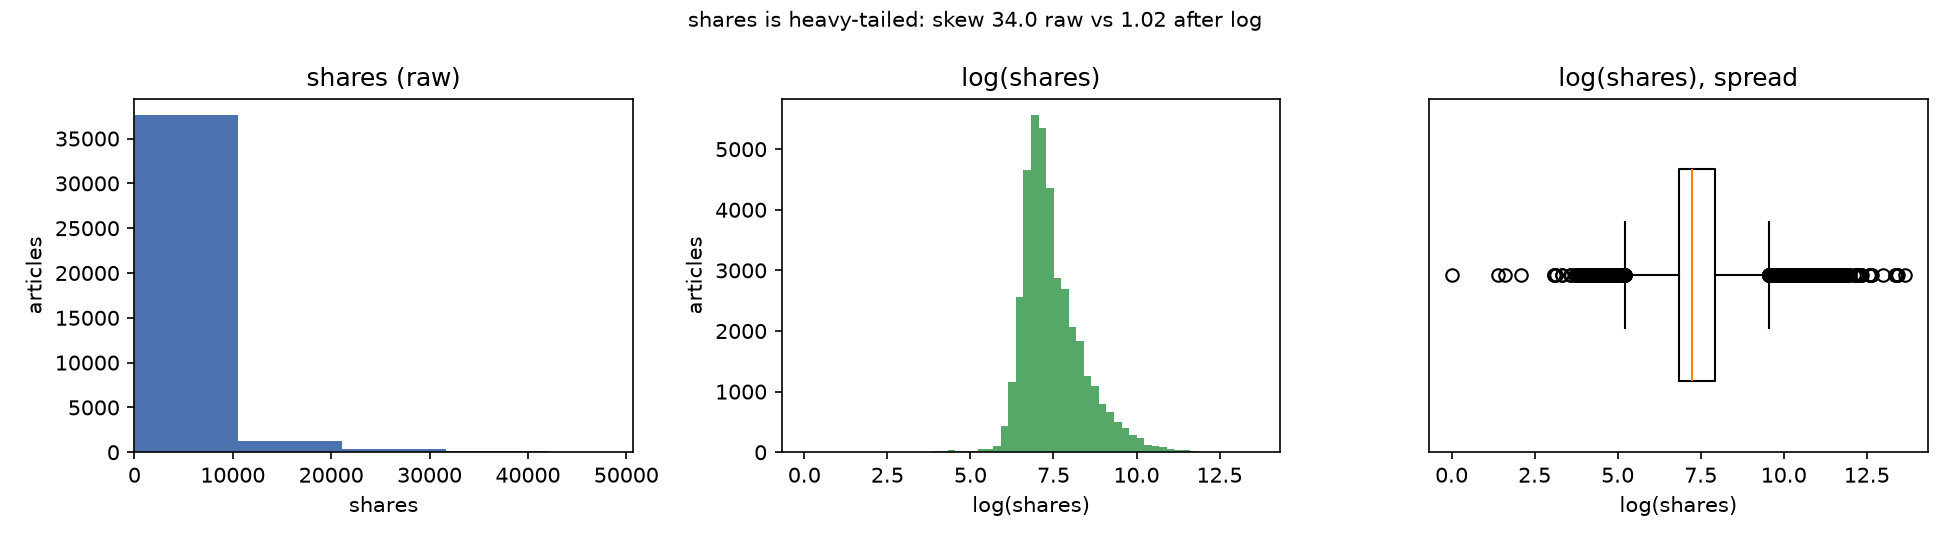

In [3]:
shares_summary = eda.shares_summary(df)
display(shares_summary)

fig_path = eda.fig_shares_distribution(df)
display(Image(filename=fig_path))

**Reading the distribution.** The mean (3 395) is 2.4× the median (1 400), the maximum is
843 300 shares and skewness is ≈ 34 — a textbook heavy right tail. The top 1 % of articles collect
≈ 22 % of all shares ever recorded. After `log`, skew falls to ≈ 1.0 and the histogram is close to
symmetric, which is exactly the shape least-squares estimators want. A handful of viral outliers
therefore cannot dominate the loss function any more.


,feature,spearman,pearson
0,kw_avg_avg,0.255622,0.221720
1,kw_max_avg,0.223291,0.109292
2,self_reference_avg_sharess,0.192174,0.087217
3,self_reference_min_shares,0.181517,0.073354
4,self_reference_max_shares,0.168725,0.077427
5,data_channel_is_world,-0.168441,-0.151651
6,LDA_02,-0.157179,-0.165034
7,is_weekend,0.151718,0.114387
8,data_channel_is_entertainment,-0.114691,-0.082504
9,data_channel_is_socmed,0.113572,0.081106


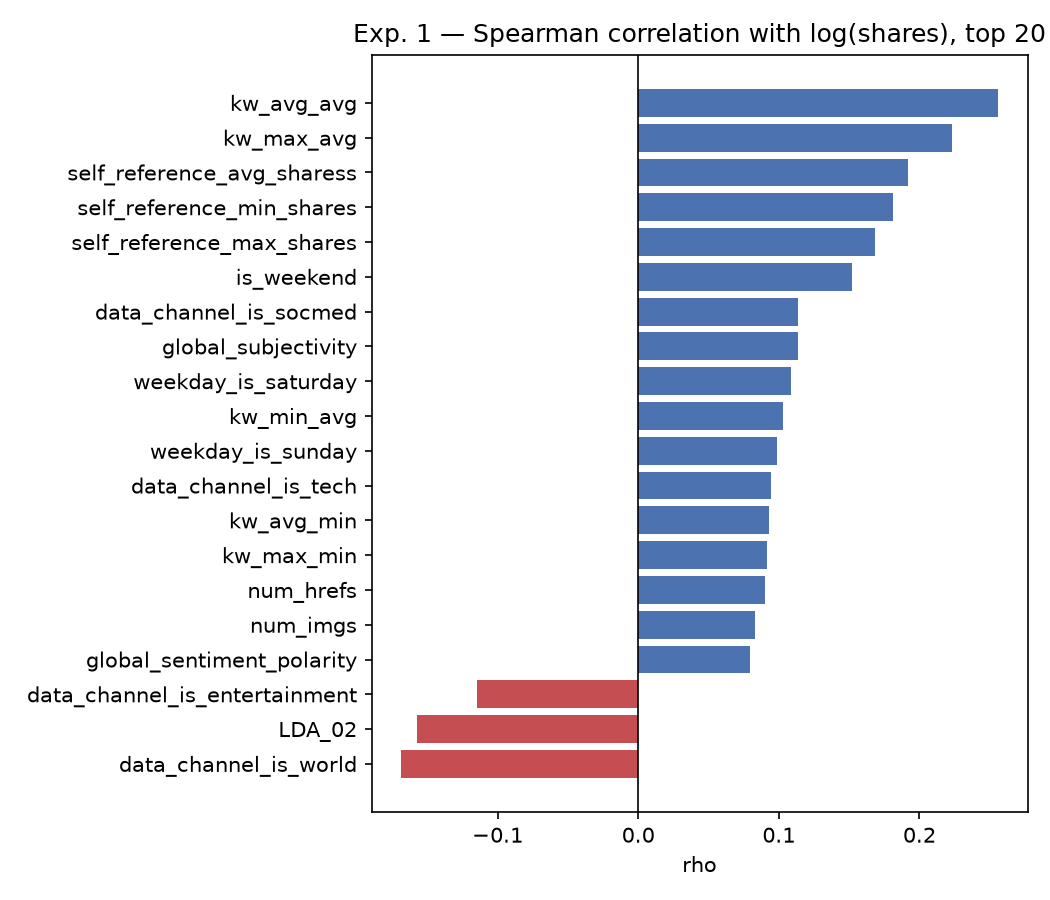

In [4]:
corr = eda.correlation_table(df, top=20)
display(corr.head(12))

fig_path = eda.fig_top_correlations(corr)
display(Image(filename=fig_path))

**Which features move with `log(shares)`?** The ranking is dominated by the `kw_*` family —
features that describe the *historical* popularity of the article's keywords on Mashable — not by
anything the journalist writes. `kw_avg_avg` (average shares of keywords in the article) reaches
ρ ≈ 0.26, `kw_max_avg` ≈ 0.22, the `self_reference_*` block ≈ 0.17–0.19. Negative correlations
(`data_channel_is_world`, `LDA_02`) mean "boring topic" rather than "bad writing".

Publishing-day flags do appear (`is_weekend` ρ ≈ +0.15) but their effect is small next to keyword
history. Raw Pearson correlations are much weaker than Spearman for the `kw_*` features because a
few enormous keyword values compress everything else — another argument for the rank view.


,channel,articles,median_shares,mean_shares
0,socmed,2323,2100.0,3629.0
1,none,6134,1900.0,5945.0
2,lifestyle,2099,1700.0,3682.0
3,tech,7346,1700.0,3072.0
4,bus,6258,1400.0,3063.0
5,entertainment,7057,1200.0,2970.0
6,world,8427,1100.0,2288.0


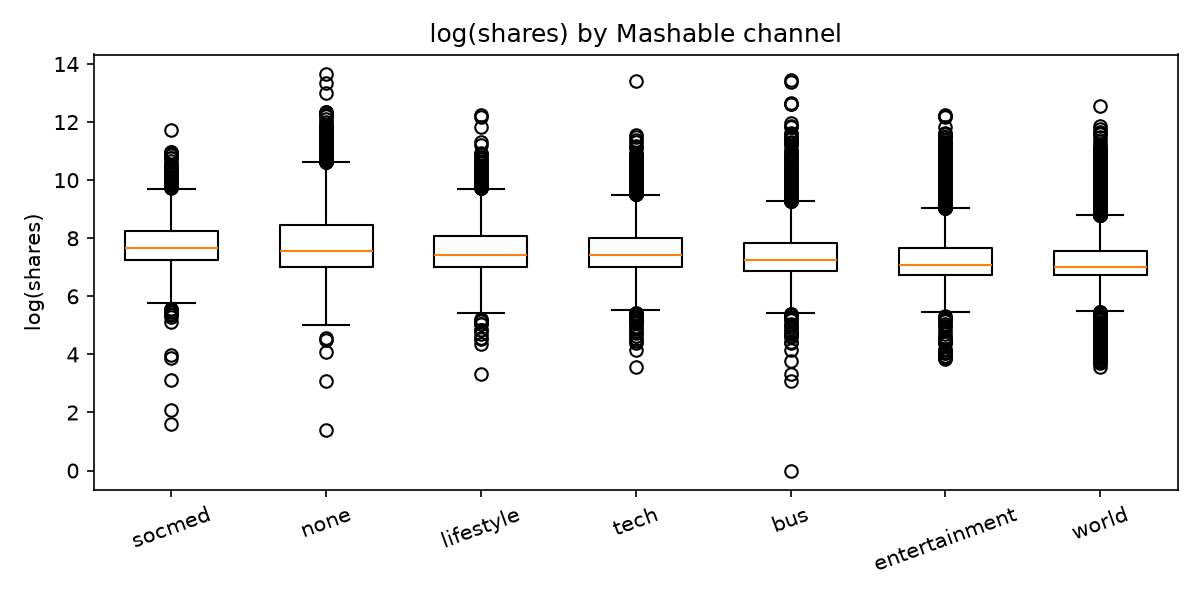

In [5]:
channels = eda.channel_table(df)
display(channels)

fig_path = eda.fig_channel_box(df)
display(Image(filename=fig_path))

Channel medians run from 1 100 shares (world news) to 2 100 (social media) — a ~2× spread in
the median, i.e. a real but modest effect, and one the model can use. Note the mean/median gap for
`none`: a few channel-less viral pieces inflate its mean.


## 3. Exp. 2 — Preprocessing: what we drop and why we model `log(shares)`

**Dropped columns**

| column | why |
|---|---|
| `url` | unique per article. It cannot generalise to an *unpublished* article and would let a tree memorise individual rows. |
| `timedelta` | days since the first article, i.e. a publication timestamp. For a genuinely *before-publication* prediction the date is unavailable, and including it lets the model memorise what happened in specific weeks (the dataset spans a fixed 2-year window). |

That leaves the 58 features the dataset documents, and keeps the promise "predict from content,
links, keywords and publishing day".

**Target.** We fit `log(shares)` and report MAE/R² after mapping predictions back with `expm1`
(clipped at 1 share). The evidence for the transform is measured, not asserted, below.


In [6]:
ds = preprocess.prepare(df)
print("features:", len(ds.feature_names))
print("train rows:", len(ds.X_train), "| test rows:", len(ds.X_test))
print("popularity threshold (training median of shares):", ds.popularity_threshold)

y_train_bin, y_test_bin = ds.binary_labels()
print("popular rate — train:", round(y_train_bin.mean(), 3), "| test:", round(y_test_bin.mean(), 3))

features: 58
train rows: 31715 | test rows: 7929
popularity threshold (training median of shares): 1400.0
popular rate — train: 0.536 | test: 0.524


In [7]:
log_vs_raw = regression.log_vs_raw_comparison(ds)
display(log_vs_raw)

,target,MAE (shares),median abs err (shares),R2 (share scale),R2 (log scale)
0,Linear Regression on raw shares,2998.7,1682.3,0.0262,-0.3898
1,Linear Regression on log(shares),2347.8,733.1,-0.0029,0.1274


**Why `log(shares)` — the measured argument.** Same model, same split, two targets, both
scored on the share scale:

* On **raw shares** the linear model predicts the conditional mean, so it is off by ~1 680 shares
  for the *typical* article while its R² looks better (≈ 0.03) — the squared error is carried by a
  single 843 300-share article.
* On **log shares** the *median* error halves to ≈ 733 shares and R² on the log scale becomes
  ≈ 0.13, which is a signal you can actually use.

R² on the raw share scale is ~0 for every model in this study, and that is the honest result: no
content feature predicts a 100× outlier. The log scale is not cheating — the metrics below are
always reported back on the original scale, so the badly-behaved tail still shows up in R².

*Scaling:* `StandardScaler` is fitted on the training rows only and used only by the scale-sensitive
models (Linear Regression, KNN, SVM). Trees are scale-invariant and get the raw frame.


## 4. Exp. 3 — Linear Regression baseline (target = `log(shares)`)

Also shown: the trivial baseline "always predict the training median", because a model that cannot
beat it on MAE is useless to a newsroom.


In [8]:
from sklearn.linear_model import LinearRegression

reg_results = {}
reg_results["Linear Regression"] = regression.evaluate(
    "Linear Regression", LinearRegression(), ds, ds.X_train_scaled, ds.X_test_scaled,
    notes="scaled features",
)

baseline_row = regression.median_baseline(ds)
display(pd.DataFrame([baseline_row, reg_results["Linear Regression"].as_row()]))

,model,MAE (shares),RMSE (shares),R2 (share scale),R2 (log scale),median abs err,fit (s),notes
0,Baseline: training median,2395.4,11152.9,-0.0308,-0.0578,600.0,0.0,constant 1400 shares
1,Linear Regression,2347.8,11000.9,-0.0029,0.1274,733.1,0.1,scaled features


Linear Regression beats the constant baseline on MAE (2 348 vs 2 395 shares) and achieves
R² ≈ 0.13 on the log scale, but its **R² on the share scale is ≈ 0.00**: it explains none of the
raw variance, because a straight line in log space converts to a monotone but low-variance guess in
share space. This is the reference point the other three regressors have to beat.


## 5. Exp. 5 — Decision Tree (regression + classification)


In [9]:
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

reg_results["Decision Tree"] = regression.evaluate(
    "Decision Tree",
    DecisionTreeRegressor(min_samples_leaf=5, random_state=config.RANDOM_STATE),
    ds, ds.X_train, ds.X_test, notes="min_samples_leaf=5",
)
display(pd.DataFrame([reg_results["Decision Tree"].as_row()]))

,model,MAE (shares),RMSE (shares),R2 (share scale),R2 (log scale),median abs err,fit (s),notes
0,Decision Tree,3019.3,11340.3,-0.0657,-0.3903,975.1,1.8,min_samples_leaf=5


A single tree is the **worst** regressor of the four (MAE ≈ 3 019, R² on the share scale
≈ −0.07): it fits training noise and its prediction for any leaf is an average over a small group
of articles, which is unstable. This is the classic variance problem that bagging fixes.


## 6. Exp. 6 — Random Forest (regression + classification)


In [10]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

reg_results["Random Forest"] = regression.evaluate(
    "Random Forest",
    RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                          random_state=config.RANDOM_STATE, n_jobs=-1),
    ds, ds.X_train, ds.X_test, notes="300 trees, min_samples_leaf=2",
)
display(pd.DataFrame([reg_results["Random Forest"].as_row()]))

,model,MAE (shares),RMSE (shares),R2 (share scale),R2 (log scale),median abs err,fit (s),notes
0,Random Forest,2316.5,10967.0,0.0033,0.1697,745.8,19.2,"300 trees, min_samples_leaf=2"


The Random Forest is the **best regressor** on every metric (MAE ≈ 2 317 shares, R² on the
share scale ≈ 0.003, R² on the log scale ≈ 0.17). The jump from "slightly worse than the median
baseline" to "meaningfully better" is the whole point of ensembling here.


## 7. Exp. 7 — KNN Regressor (k chosen on a training-only validation slice)

KNN is distance-based, so it uses the standardised matrix. `k` is picked on a 15 % slice of the
**training** data — the test set is never touched for model selection.


In [11]:
knn_k, knn_tuning = regression.tune_knn_k(ds, candidates=(5, 15, 35, 75))
display(knn_tuning)
print("chosen k =", knn_k)

,k,val_MAE(log)
0,75,0.6364
1,35,0.6394
2,15,0.6472
3,5,0.6921


chosen k = 75


In [12]:
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

reg_results[f"KNN Regressor (k={knn_k})"] = regression.evaluate(
    f"KNN Regressor (k={knn_k})",
    KNeighborsRegressor(n_neighbors=knn_k, weights="distance", n_jobs=-1),
    ds, ds.X_train_scaled, ds.X_test_scaled,
    notes=f"k={knn_k}, distance weights",
)
display(pd.DataFrame([reg_results[f"KNN Regressor (k={knn_k})"].as_row()]))

,model,MAE (shares),RMSE (shares),R2 (share scale),R2 (log scale),median abs err,fit (s),notes
0,KNN Regressor (k=75),2334.9,11034.9,-0.0091,0.1077,703.8,0.0,"k=75, distance weights"


KNN lands between Linear Regression and the Random Forest. With 58 mostly-0/1 features in
58-dimensional space, "nearest neighbours" are not very near — but it has the **lowest median
absolute error** (≈ 704 shares), i.e. it is decent on typical articles and fails on the tail.


,model,MAE (shares),RMSE (shares),R2 (share scale),R2 (log scale),median abs err,fit (s),notes
3,Random Forest,2316.5,10967.0,0.0033,0.1697,745.8,19.2,"300 trees, min_samples_leaf=2"
4,KNN Regressor (k=75),2334.9,11034.9,-0.0091,0.1077,703.8,0.0,"k=75, distance weights"
1,Linear Regression,2347.8,11000.9,-0.0029,0.1274,733.1,0.1,scaled features
0,Baseline: training median,2395.4,11152.9,-0.0308,-0.0578,600.0,0.0,constant 1400 shares
2,Decision Tree,3019.3,11340.3,-0.0657,-0.3903,975.1,1.8,min_samples_leaf=5


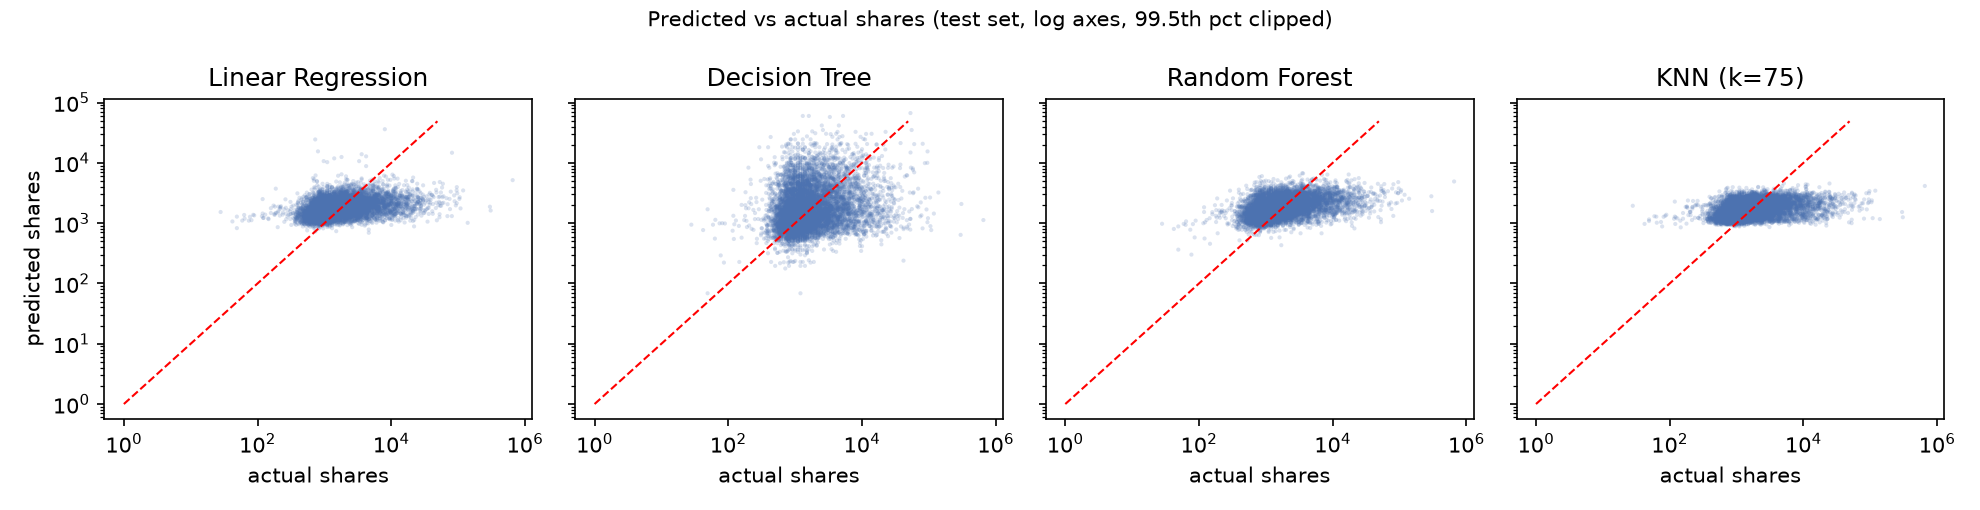

In [13]:
comparison = pd.concat(
    [pd.DataFrame([baseline_row])] + [pd.DataFrame([r.as_row()]) for r in reg_results.values()],
    ignore_index=True,
).sort_values("MAE (shares)")
display(comparison)

display(Image(filename=regression.fig_predicted_vs_actual(
    {k: v.model for k, v in reg_results.items()}, ds)))

**Regression verdict.** All four models cluster at MAE ≈ 2 300–3 000 shares and R² ≈ 0 on
the original scale; the Random Forest wins on every aggregate metric, the Decision Tree loses badly.
In the scatter panels the predictions form a narrow vertical band: the models have learned "the
average article", not "this article will go viral". Everything above ~50 000 shares is systematically
under-predicted. That is not a tuning failure, it is the ceiling of the feature set.


## 8. Exp. 4 — Classification: popular vs not at the training median

`popular := shares >= 1 400` (the **training** median). The threshold is fixed on training data and
applied unchanged to the test rows; the resulting test split (≈ 52 % popular) is close to balanced,
so F1 on the popular class is a fair headline metric. Exp. 4 fits **Logistic Regression**; the other
four families are fitted in the cells that follow.


In [14]:
from sklearn.linear_model import LogisticRegression

clf_results = {}
clf_results["Logistic Regression"] = classification.evaluate(
    "Logistic Regression",
    LogisticRegression(max_iter=2000, C=1.0, random_state=config.RANDOM_STATE),
    ds, ds.X_train_scaled, ds.X_test_scaled, notes="scaled features, C=1",
)
display(pd.DataFrame([clf_results["Logistic Regression"].as_row()]))
display(classification.confusion(clf_results, ds, "Logistic Regression"))

,model,accuracy,precision,recall,F1 (popular),ROC-AUC,fit (s),notes
0,Logistic Regression,0.6523,0.6581,0.7004,0.6786,0.7053,0.2,"scaled features, C=1"


,pred: not popular,pred: popular
actual: not popular,2262,1512
actual: popular,1245,2910


F1 ≈ 0.68 (accuracy ≈ 0.65) — clearly above the 0.5 you would get from always guessing
"popular", so the features carry real signal. The confusion matrix shows the characteristic pattern:
recall (0.70) is higher than precision (0.66), because the model leans towards "popular" whenever the
keyword history looks good.


## 9. Exp. 5–7 — the same families as classifiers

Same split, same labels, only the loss changes (log-loss / Gini / majority vote instead of squared
error). Classification is the easier problem: the median split throws away the impossible tail and
asks only "above or below the middle?".


In [15]:
clf_results["Decision Tree"] = classification.evaluate(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=config.RANDOM_STATE),
    ds, ds.X_train, ds.X_test, notes="max_depth=8, min_samples_leaf=20",
)
clf_results["Random Forest"] = classification.evaluate(
    "Random Forest",
    RandomForestClassifier(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                           random_state=config.RANDOM_STATE, n_jobs=-1),
    ds, ds.X_train, ds.X_test, notes="300 trees, min_samples_leaf=2",
)
clf_results["KNN"] = classification.evaluate(
    f"KNN (k={knn_k})",
    KNeighborsClassifier(n_neighbors=knn_k, weights="distance", n_jobs=-1),
    ds, ds.X_train_scaled, ds.X_test_scaled, notes=f"k={knn_k}, distance weights",
)
display(pd.DataFrame([clf_results[k].as_row() for k in ("Decision Tree", "Random Forest", "KNN")]))

,model,accuracy,precision,recall,F1 (popular),ROC-AUC,fit (s),notes
0,Decision Tree,0.6399,0.6457,0.6934,0.6687,0.6875,1.1,"max_depth=8, min_samples_leaf=20"
1,Random Forest,0.6664,0.6649,0.7326,0.6971,0.7264,18.3,"300 trees, min_samples_leaf=2"
2,KNN (k=75),0.6407,0.6571,0.6573,0.6572,0.6902,0.0,"k=75, distance weights"


## 10. Exp. 8 — SVM classifier and the full comparison

An RBF SVM costs roughly O(n²)–O(n³) in training rows; on this machine it needs ~130 s for the full
31 715-row training set, which is acceptable, so **no subsample is used** here (in `src.run_all` the
same full-data setting is the default). `SVC(probability=False)` exposes `decision_function`, which is
enough for ROC-AUC.


In [16]:
from sklearn.svm import SVC

clf_results["SVM (RBF)"] = classification.evaluate(
    "SVM (RBF)",
    SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000),
    ds, ds.X_train_scaled, ds.X_test_scaled, notes="RBF kernel, C=1, gamma='scale', full training set",
)
display(pd.DataFrame([clf_results["SVM (RBF)"].as_row()]))

clf_comparison = pd.DataFrame([r.as_row() for r in clf_results.values()]).sort_values(
    "F1 (popular)", ascending=False
)
display(clf_comparison)

,model,accuracy,precision,recall,F1 (popular),ROC-AUC,fit (s),notes
0,SVM (RBF),0.6559,0.6588,0.7124,0.6846,0.7142,121.6,"RBF kernel, C=1, gamma='scale', full training set"


,model,accuracy,precision,recall,F1 (popular),ROC-AUC,fit (s),notes
2,Random Forest,0.6664,0.6649,0.7326,0.6971,0.7264,18.3,"300 trees, min_samples_leaf=2"
4,SVM (RBF),0.6559,0.6588,0.7124,0.6846,0.7142,121.6,"RBF kernel, C=1, gamma='scale', full training set"
0,Logistic Regression,0.6523,0.6581,0.7004,0.6786,0.7053,0.2,"scaled features, C=1"
1,Decision Tree,0.6399,0.6457,0.6934,0.6687,0.6875,1.1,"max_depth=8, min_samples_leaf=20"
3,KNN (k=75),0.6407,0.6571,0.6573,0.6572,0.6902,0.0,"k=75, distance weights"


,pred: not popular,pred: popular
actual: not popular,2240,1534
actual: popular,1111,3044


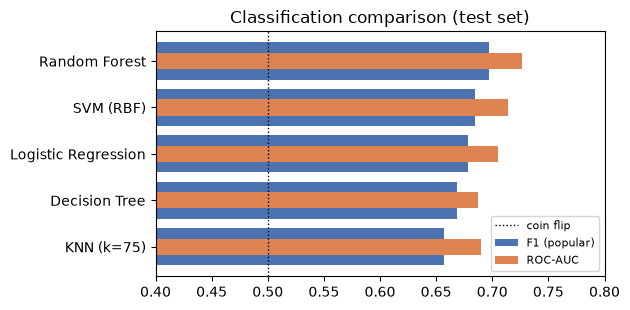

In [17]:
display(classification.confusion(clf_results, ds, "Random Forest"))

fig, ax = plt.subplots(figsize=(6.4, 3.2))
order = clf_comparison.sort_values("F1 (popular)")
ax.barh(order["model"], order["F1 (popular)"], color="#4c72b0", label="F1 (popular)")
ax.barh(order["model"], order["ROC-AUC"], height=0.35, color="#dd8452", label="ROC-AUC")
ax.axvline(0.5, color="k", ls=":", lw=1, label="coin flip")
ax.set(xlim=(0.4, 0.8), title="Classification comparison (test set)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

**Classification verdict.** Random Forest is best (F1 ≈ 0.70, AUC ≈ 0.73), SVM and Logistic
Regression close behind (F1 ≈ 0.685 / 0.679), KNN weakest (0.657). Every model sits in a narrow
0.66–0.70 band: swapping the algorithm changes less than the choice of target does. Remember that a
0.70 F1 here is only "which side of 1 400 shares will this land on" — the magnitude is still a coin
flip, as the regression results show.


## 11. Interpretation — which features matter, and what they are proxies for


In [18]:
lin_coefs = interpret.linear_coefficients(clf_results["Logistic Regression"].model, ds, top=12)
display(lin_coefs)

rf_clf = clf_results["Random Forest"].model
rf_reg = reg_results["Random Forest"].model
display(interpret.forest_importances(rf_reg, ds, top=12))

,feature,coef_log_shares
0,n_non_stop_words,1.523245
1,n_non_stop_unique_tokens,-1.013628
2,kw_avg_avg,0.942376
3,kw_max_avg,-0.555428
4,n_unique_tokens,-0.477595
5,data_channel_is_tech,0.233856
6,data_channel_is_socmed,0.227363
7,LDA_00,0.183827
8,self_reference_min_shares,0.147330
9,is_weekend,0.146898


,feature,importance
0,kw_avg_avg,0.076812
1,kw_max_avg,0.049715
2,self_reference_avg_sharess,0.036083
3,self_reference_min_shares,0.032135
4,kw_avg_max,0.031958
5,LDA_01,0.030165
6,LDA_04,0.029293
7,global_subjectivity,0.028862
8,kw_avg_min,0.028576
9,average_token_length,0.028428


The standardised logistic coefficients are led by `n_non_stop_words` (+1.52) and
`n_non_stop_unique_tokens` (−1.01). Treat those two with suspicion: they are ratio features with
degenerate values for the 1 181 empty articles and for very short posts, so the coefficient is
mostly an artefact of a handful of rows, not editorial advice. `kw_avg_avg` (+0.94) is the first
*meaningful* term, and it is a history proxy.

Impurity importance agrees: `kw_avg_avg` (≈ 0.077), `kw_max_avg` (≈ 0.050), then
`self_reference_avg_sharess`, LDA topic weights and readability measures. Impurity importance
favours continuous, high-cardinality columns, so it is cross-checked with permutation importance
next.


,feature,importance_mean,importance_std
0,kw_avg_avg,0.056528,0.001965
1,kw_max_avg,0.019594,0.001125
2,self_reference_avg_sharess,0.017214,0.002660
3,is_weekend,0.015828,0.000960
4,self_reference_min_shares,0.012726,0.002193
5,kw_max_max,0.011609,0.001098
6,num_hrefs,0.006354,0.000819
7,data_channel_is_tech,0.005745,0.001455
8,LDA_00,0.005171,0.000849
9,n_unique_tokens,0.004737,0.001046


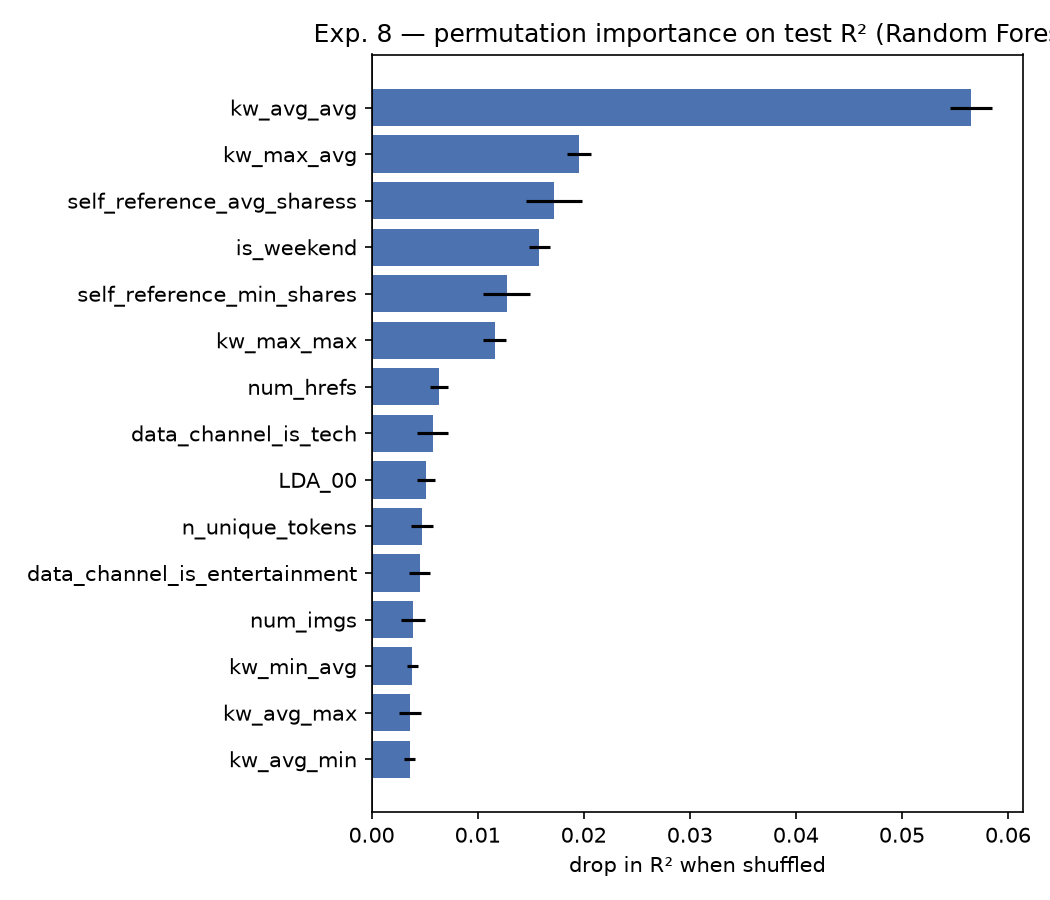

In [19]:
perm = interpret.permutation_table(rf_reg, ds, n_repeats=5, top=15)
display(perm)
display(Image(filename=interpret.fig_importance(perm)))

Permutation importance on the test set (drop in R² when a column is shuffled) is the honest
ranking: `kw_avg_avg` alone is worth ≈ 0.057 of test R², then `kw_max_avg` (≈ 0.020),
`self_reference_avg_sharess` (≈ 0.017) and `is_weekend` (≈ 0.016) are a long way back. Everything
else contributes < 0.013. Note what is *absent*: article length, image and video counts, sentiment
and subjectivity barely matter.


,feature_group,share_of_importance
0,content & links,33.5
1,keywords (kw_*),23.9
2,LDA topics,15.0
3,title / subjectivity / polarity,12.9
4,self-reference shares,8.0
5,channel,3.5
6,publishing day,3.3


,bucket,share_of_importance_%
0,"article history on Mashable (kw_*, self_refere...",31.9
1,"article content, links, topics, timing",68.1


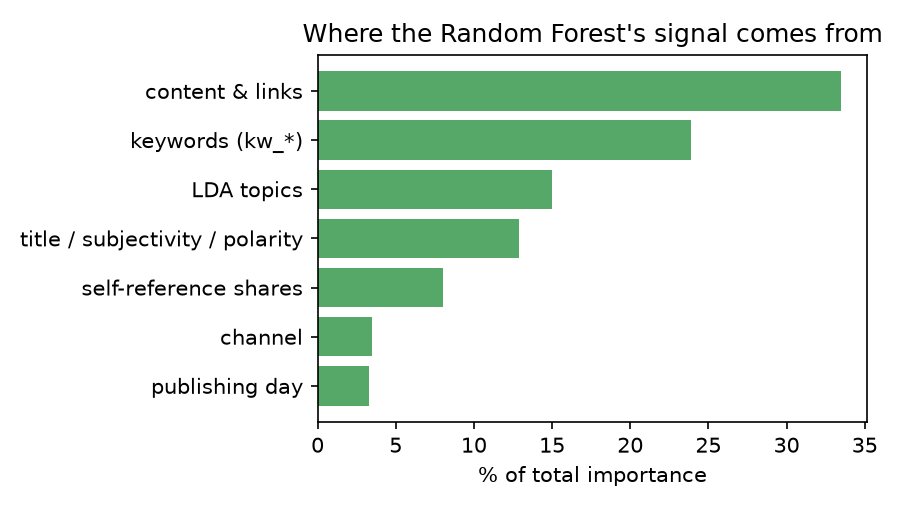

In [20]:
grouped = interpret.group_feature_importance(rf_clf, ds)
display(grouped)

bucket = interpret.history_vs_content_split(grouped)
display(bucket)
display(Image(filename=interpret.fig_group_importance(grouped)))

**Where the signal comes from.** Roughly **one third** of the model's total importance
(≈ 32 %) sits in features that describe Mashable's *own past behaviour* — `kw_*` keyword-share
history and `self_reference_*` shares of previously linked articles — while content, links, topics
and timing share the other two thirds. In other words, the strongest predictor of how a new article
will do is how similar articles recently did on the same site. That is a self-fulfilling signal: it
works only while the site's audience behaves the way it always has.


## 12. Honest limitations — what article features cannot capture

1. **The ceiling is real.** R² on the share scale is ≈ 0.00 for all four regressors. Against a
   constant-median baseline (MAE ≈ 2 395) the best model saves ~80 shares ≈ 3 %. That is a weak
   tool for predicting *magnitude*; it is a usable tool for ranking articles into "likely popular /
   likely not" (F1 ≈ 0.70).
2. **The tail is unmodellable from content.** The 843 300-share article and the top 1 % that own
   22 % of all shares are driven by events outside the article: front-page placement, a celebrity
   sharing it, a news cycle, a competitor's outage. No column records the audience, the referrer, the
   hour, or the other stories published that day.
3. **History proxies leak the future past.** `kw_avg_avg` and `self_reference_*` are computed from
   shares of earlier articles. They are legitimate "available before publication" features, but they
   encode the site's past distribution — if Mashable's audience or the Facebook algorithm changes,
   they decay silently.
4. **The median split flatters the models.** Balanced classes by construction, and "popular" means
   "above 1 400", not "viral". A model with F1 0.70 says nothing about the 100 000-share articles
   that matter commercially.
5. **Two ratio features are broken.** `n_non_stop_words` / `n_non_stop_unique_tokens` take degenerate
   values on empty or ultra-short articles and dominate the linear coefficients. A production version
   would repair or drop them; we keep them to stay comparable with published baselines, and say so.
6. **The dataset is one site, one era.** Mashable 2013–2015, Facebook-dominant distribution. Any
   number here is a statement about that corpus, not about "news" in general.
7. **Single split.** One 80/20 hold-out means the ~±0.02 noise on F1 between neighbouring models is
   not resolvable. Cross-validation would tighten the comparison but not change the conclusions.


In [21]:
summary_path = config.RESULT_DIR / "summary.json"
print("artefacts written by this analysis:")
for p in sorted(config.RESULT_DIR.glob("*")):
    print("  ", p.relative_to(ROOT))
for p in sorted(config.FIG_DIR.glob("*.png")):
    print("  ", p.relative_to(ROOT))
print("   models/model_bundle.joblib")

artefacts written by this analysis:
   reports\results\00_row_count.csv
   reports\results\01_sanity.csv
   reports\results\exp1_channels.csv
   reports\results\exp1_correlations.csv
   reports\results\exp1_shares_summary.csv
   reports\results\exp2_log_vs_raw_target.csv
   reports\results\exp2_split_info.json
   reports\results\exp3_7_regression.csv
   reports\results\exp3_quintile_calibration.csv
   reports\results\exp4_8_classification.csv
   reports\results\exp7_knn_k_tuning.csv
   reports\results\exp8_confusion_logistic.csv
   reports\results\exp8_confusion_random.csv
   reports\results\exp8_group_importance.csv
   reports\results\exp8_history_vs_content.csv
   reports\results\exp8_logistic_coefficients.csv
   reports\results\exp8_permutation_importance.csv
   reports\results\exp8_rf_importance_classification.csv
   reports\results\exp8_rf_importance_regression.csv
   reports\results\summary.json
   reports\figures\exp1_channel_box.png
   reports\figures\exp1_shares_distribution.p

## 13. Reproducing this notebook

```bash
python -m venv .venv                 # Python 3.14 (3.15 on this machine blocks pandas' DLLs)
.venv\Scripts\pip install -r requirements.txt
python -m src.run_all                # ~6 min: every CSV, figure and the demo model bundle
jupyter lab notebooks/P11_online_news_popularity.ipynb
```

Live demo (10-minute presentation): `python demo/predict_demo.py --interactive` loads
`models/model_bundle.joblib` and scores an article you describe on the command line.
